In [18]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import os

/var/folders/76/2s_xpvh90mb6kmqg7v55sjxr0000gn/T/ipykernel_53080/3414055987.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Model", y="IoU", data=df, palette=["#4C72B0", "#55A868", "#C44E52"])


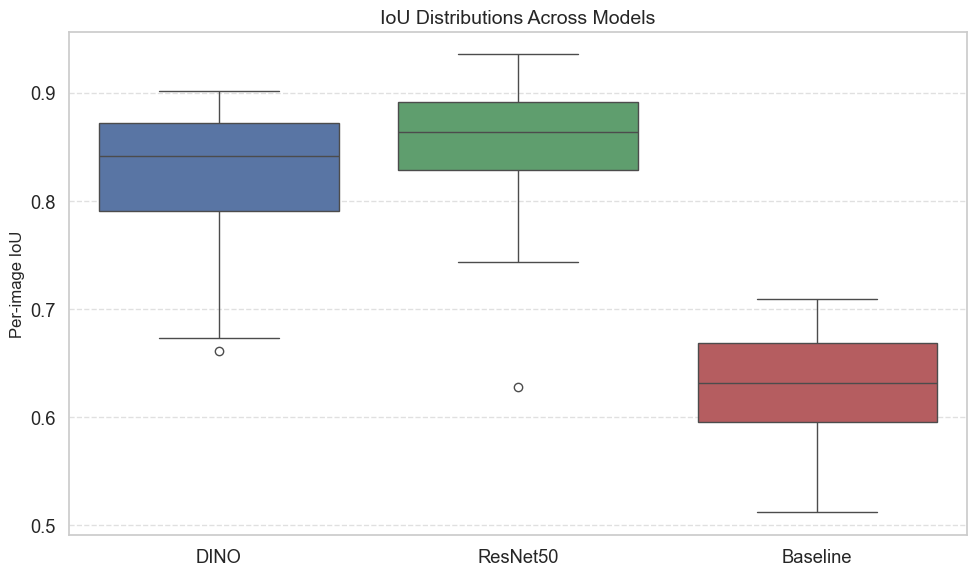

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define model file paths
iou_paths = {
    "DINO": [f"exports/dino/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{fold}.npy" for fold in range(1, 6)],
    "ResNet50": [f"exports/unet/resnet_np/resnet50_per_image_iou_fold{fold}.npy" for fold in range(1, 6)],
    "Baseline": [f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy" for fold in range(1, 6)],
}

# Load data and create a clean DataFrame
data = []
for model_name, file_list in iou_paths.items():
    for file_path in file_list:
        ious = np.load(file_path)
        for score in ious:
            data.append({"Model": model_name, "IoU": score})

df = pd.DataFrame(data)

# Plot
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(10, 6))
sns.boxplot(x="Model", y="IoU", data=df, palette=["#4C72B0", "#55A868", "#C44E52"])
plt.title("IoU Distributions Across Models", fontsize=14)
plt.ylabel("Per-image IoU", fontsize=12)
plt.xlabel("")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

/var/folders/76/2s_xpvh90mb6kmqg7v55sjxr0000gn/T/ipykernel_53080/2172898513.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(bootstrapped_means.values(), labels=bootstrapped_means.keys(), patch_artist=True)


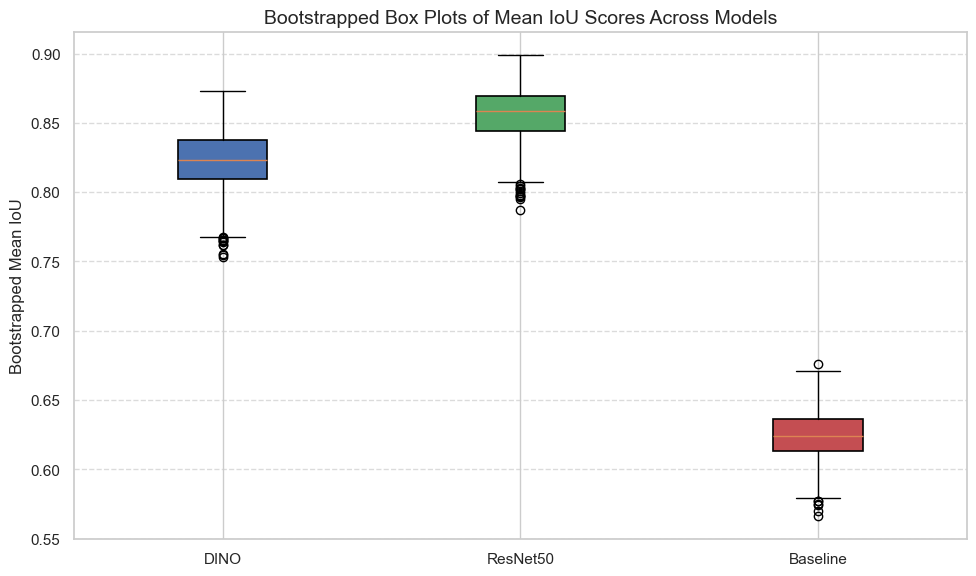

In [70]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set seed for reproducibility
np.random.seed(42)

# Paths for each fold

paths = {
    "DINO": [f"exports/dino/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{fold}.npy" for fold in range(1, 6)],
    "ResNet50": [f"exports/unet/resnet_np/resnet50_per_image_iou_fold{fold}.npy" for fold in range(1, 6)],
    "Baseline": [f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy" for fold in range(1, 6)]
}

# Load all IoU scores
iou_data = {model: [] for model in paths}
for model, model_paths in paths.items():
    for path in model_paths:
        ious = np.load(path)
        iou_data[model].extend(ious)

# Bootstrap the mean IoU scores
bootstrapped_means = {model: [] for model in iou_data}
n_iterations = 1000
sample_size = len(iou_data["DINO"]) // 5  # Average per fold



for model, scores in iou_data.items():
    scores = np.array(scores)
    for _ in range(n_iterations):
        sample = np.random.choice(scores, size=sample_size, replace=True)
        bootstrapped_means[model].append(np.mean(sample))

# Create boxplot
colors = ['#4C72B0', '#55A868', '#C44E52']  # blue, green, red
plt.figure(figsize=(10, 6))
box = plt.boxplot(bootstrapped_means.values(), labels=bootstrapped_means.keys(), patch_artist=True)

# Set custom colors
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.2)

# Style adjustments
plt.ylabel("Bootstrapped Mean IoU", fontsize=12)
plt.title("Bootstrapped Box Plots of Mean IoU Scores Across Models", fontsize=14)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/var/folders/76/2s_xpvh90mb6kmqg7v55sjxr0000gn/T/ipykernel_53080/1658063937.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(simulated_data.values(), labels=simulated_data.keys(), patch_artist=True)


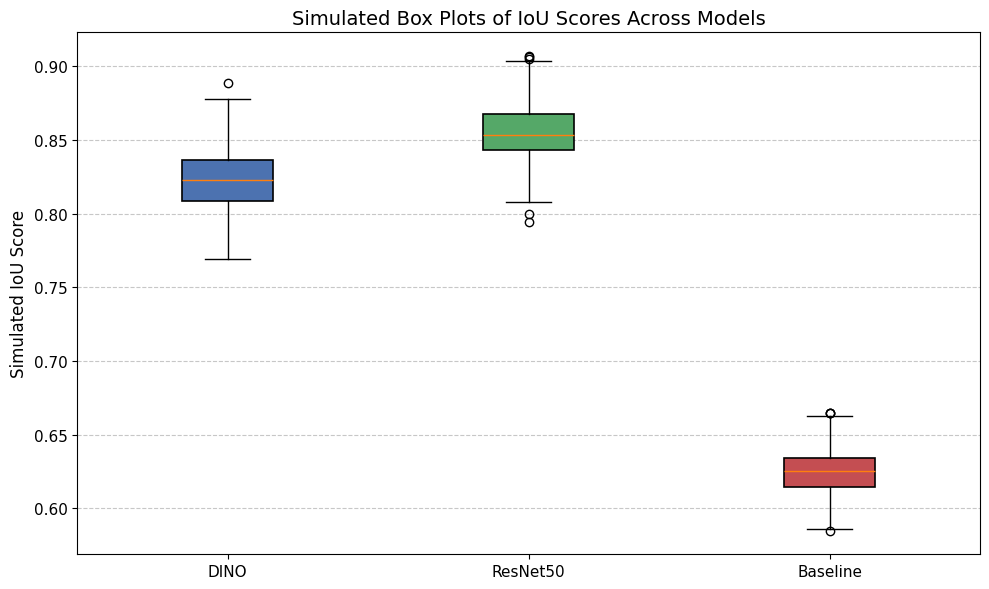

In [52]:

# Paths for each model's fold files
models = {
    "DINO": [f"exports/dino/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{fold}.npy" for fold in range(1, 6)],
    "ResNet50": [f"exports/unet/resnet_np/resnet50_per_image_iou_fold{fold}.npy" for fold in range(1, 6)],
    "Baseline": [f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy" for fold in range(1, 6)]
}

# For storing simulated samples
simulated_data = {}

# Compute mean, std and simulate data from normal dist
for model_name, file_list in models.items():
    fold_means = []
    fold_stds = []
    for path in file_list:
        ious = np.load(path)
        fold_means.append(np.mean(ious))
        fold_stds.append(np.std(ious, ddof=1))
    
    mean = np.mean(fold_means[:5])  # use only 5 folds as mentioned
    std = np.std(fold_means[:5], ddof=1)
    n = 5
    t_critical = stats.t.ppf(0.975, df=n-1)
    ci_lower = mean - t_critical * (std / np.sqrt(n))
    ci_upper = mean + t_critical * (std / np.sqrt(n))
    
    # Simulate 500 samples from the normal distribution with mean and std
    simulated = np.random.normal(loc=mean, scale=std, size=500)
    simulated_data[model_name] = simulated

# Plotting the boxplot with custom colors for academic report
colors = ['#4C72B0', '#55A868', '#C44E52']  # blue, green, red
plt.figure(figsize=(10, 6))
box = plt.boxplot(simulated_data.values(), labels=simulated_data.keys(), patch_artist=True)

# Set custom colors
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.2)

# Style adjustments
plt.ylabel("Simulated IoU Score", fontsize=12)
plt.title("Simulated Box Plots of IoU Scores Across Models", fontsize=14)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

ResNet: Mean = 0.8577, Std = 0.0130, 95% CI = [0.8254, 0.8900]
DINO: Mean = 0.8479, Std = 0.0202, 95% CI = [0.7976, 0.8982]
Baseline: Mean = 0.6249, Std = 0.0501, 95% CI = [0.5004, 0.7494]


/var/folders/76/2s_xpvh90mb6kmqg7v55sjxr0000gn/T/ipykernel_53080/708230366.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(simulated_data, patch_artist=True, labels=labels)


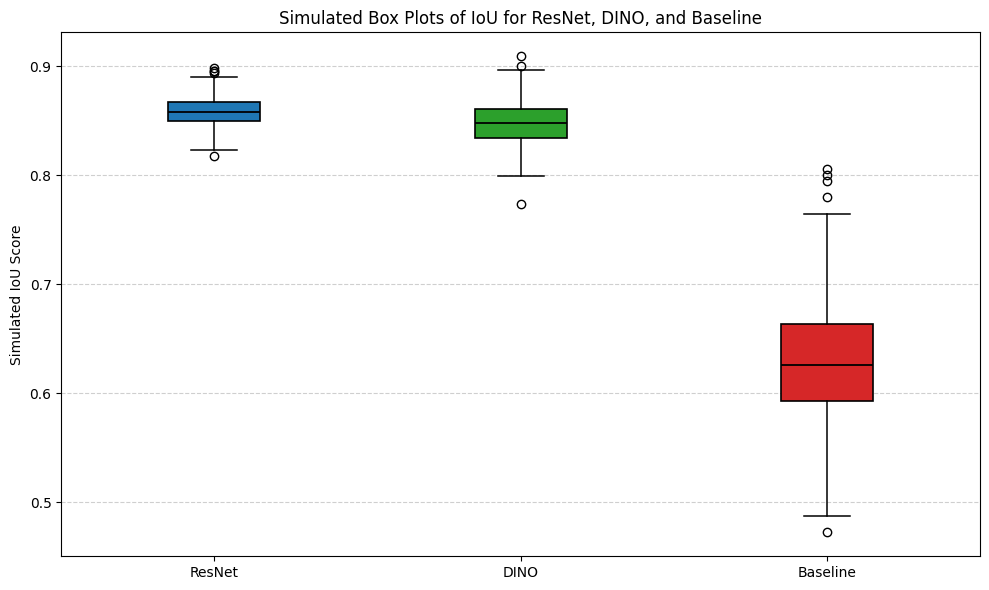

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# === Input: mean and std for each config ===
means = [0.8577, 0.8479, 0.6249]  # ResNet, DINO, Baseline
stds = [0.013, 0.02024, 0.0501]
n = 3  # folds

simulated_data = []
labels = ['ResNet', 'DINO', 'Baseline']
ci_bounds = []

# Simulate data and compute 95% confidence intervals
for i in range(len(means)):
    mean = means[i]
    std = stds[i]
    
    sem = std / np.sqrt(n)
    t_value = stats.t.ppf(0.975, df=n-1)
    ci_lower = mean - t_value * sem
    ci_upper = mean + t_value * sem
    ci_bounds.append((ci_lower, ci_upper))
    
    # Simulate points for visual boxplot
    simulated_points = np.random.normal(loc=mean, scale=std, size=500)
    simulated_data.append(simulated_points)

# Set consistent style
colors = ['#1f77b4', '#2ca02c', '#d62728']  # ResNet, DINO, Baseline

plt.figure(figsize=(10, 6))
box = plt.boxplot(simulated_data, patch_artist=True, labels=labels)

for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.2)

for whisker in box['whiskers']:
    whisker.set(color='black', linewidth=1.1)

for cap in box['caps']:
    cap.set(color='black', linewidth=1.1)

for median in box['medians']:
    median.set(color='black', linewidth=1.3)

plt.ylabel('Simulated IoU Score')
plt.title('Simulated Box Plots of IoU for ResNet, DINO, and Baseline')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# Print confidence intervals
for label, mean, std, (ci_lower, ci_upper) in zip(labels, means, stds, ci_bounds):
    print(f"{label}: Mean = {mean:.4f}, Std = {std:.4f}, 95% CI = [{ci_lower:.4f}, {ci_upper:.4f}]")

plt.show()

Config 1: Mean = 0.8577, Std = 0.0130, 95% CI = [0.8254, 0.8900]
Config 2: Mean = 0.8576, Std = 0.0140, 95% CI = [0.8228, 0.8924]
Config 3: Mean = 0.8569, Std = 0.0200, 95% CI = [0.8072, 0.9066]
Config 4: Mean = 0.8569, Std = 0.0200, 95% CI = [0.8072, 0.9066]


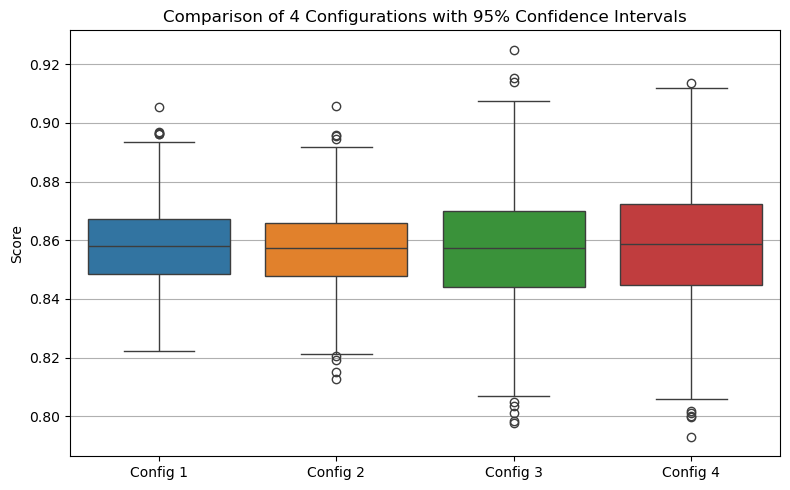

In [5]:
# === Input: mean and std for each config ===
means = [0.8577,0.8576,0.8569,0.8569]
stds  = [0.013,0.014,0.020,0.020]

# Assume n = 3 folds
n = 3

# Prepare data and print 95% CIs
simulated_data = []
labels = []

for i in range(len(means)):
    mean = means[i]
    std = stds[i]
    
    # 95% CI: mean ± t * (std / sqrt(n))
    sem = std / np.sqrt(n)
    t_value = stats.t.ppf(0.975, df=n-1)
    ci_lower = mean - t_value * sem
    ci_upper = mean + t_value * sem
    
    print(f"Config {i+1}: Mean = {mean:.4f}, Std = {std:.4f}, 95% CI = [{ci_lower:.4f}, {ci_upper:.4f}]")
    
    # Simulate n points for boxplot
    simulated_points = np.random.normal(loc=mean, scale=std, size=1000)
    simulated_data.append(simulated_points)
    labels.append(f'Config {i+1}')

# === Plot boxplots ===
plt.figure(figsize=(8, 5))
sns.boxplot(data=simulated_data)
plt.xticks(ticks=np.arange(len(labels)), labels=labels)
plt.ylabel('Score')
plt.title('Comparison of 4 Configurations with 95% Confidence Intervals')
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

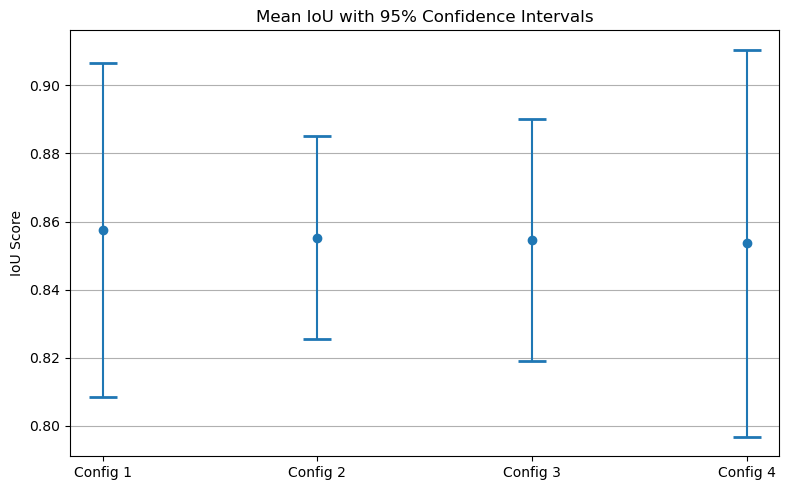

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

means = np.array([0.8575,0.8553,0.8546,0.8536])
stds  = np.array([0.0198,0.0120,0.0143,0.0229])
n = 3

# Calculate 95% CI
sem = stds / np.sqrt(n)
t_value = stats.t.ppf(0.975, df=n-1)
ci_half_width = t_value * sem

# Plot
labels = [f'Config {i+1}' for i in range(len(means))]
x_pos = np.arange(len(means))

plt.figure(figsize=(8,5))
plt.errorbar(x_pos, means, yerr=ci_half_width, fmt='o', capsize=10, capthick=2)
plt.xticks(x_pos, labels)
plt.ylabel('IoU Score')
plt.title('Mean IoU with 95% Confidence Intervals')
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

In [41]:
#Friedman test
import numpy as np
from scipy.stats import friedmanchisquare

for fold in range(1, 6):
    iou_dino      = np.load(f"exports/dino/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{fold}.npy")
    iou_resnet50  = np.load(f"exports/unet/resnet_np/resnet50_per_image_iou_fold{fold}.npy")
    iou_baseline  = np.load(f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy")

# Make sure they have the same length (same images)
assert len(iou_dino) == len(iou_resnet50) == len(iou_baseline), "Mismatch in number of images!"

# Run Friedman test
statistic, p_value = friedmanchisquare(iou_dino, iou_resnet50, iou_baseline)

# Print results
print(f"Friedman test statistic: {statistic:.4f}, p-value: {p_value:.4f}")

# Interpret
alpha = 0.05
if p_value < alpha:
    print("→ Significant differences between models (reject H0)")
else:
    print("→ No significant differences between models (fail to reject H0)")


Friedman test statistic: 13.0000, p-value: 0.0015
→ Significant differences between models (reject H0)


In [60]:
import numpy as np
import scikit_posthocs as sp
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize lists to gather all IoUs across all folds
all_iou_dino = []
all_iou_resnet = []
all_iou_baseline = []

# Loop over all 5 folds
for fold in range(1, 6):

    
    iou_dino      = np.load(f"exports/dino/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{fold}.npy")
    iou_resnet50  = np.load(f"exports/unet/resnet_np/resnet50_per_image_iou_fold{fold}.npy")
    iou_baseline  = np.load(f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy")

    print(f"Fold {fold}: DINO={len(iou_dino)}, ResNet50={len(iou_resnet50)}, Baseline={len(iou_baseline)}")


    # Ensure consistency
    assert len(iou_dino) == len(iou_resnet50) == len(iou_baseline), f"Mismatch in fold {fold}"

    # Extend lists
    all_iou_dino.extend(iou_dino)
    all_iou_resnet.extend(iou_resnet50)
    all_iou_baseline.extend(iou_baseline)

# Stack into shape (num_samples, 3)
data = np.vstack([all_iou_dino, all_iou_resnet, all_iou_baseline]).T

# Run the Nemenyi test
nemenyi_result = sp.posthoc_nemenyi_friedman(data)

# Print result
print("Combined Nemenyi post-hoc test (p-values):")
print(nemenyi_result)


Fold 1: DINO=9, ResNet50=9, Baseline=9
Fold 2: DINO=8, ResNet50=8, Baseline=8
Fold 3: DINO=8, ResNet50=8, Baseline=8
Fold 4: DINO=8, ResNet50=8, Baseline=8
Fold 5: DINO=8, ResNet50=8, Baseline=8
Combined Nemenyi post-hoc test (p-values):
          0             1             2
0  1.000000  3.894644e-03  3.526492e-06
1  0.003895  1.000000e+00  2.109424e-15
2  0.000004  2.109424e-15  1.000000e+00


In [50]:
import numpy as np
import os

# Define file paths
file_paths = {
    "DINO": [f"exports/dino/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{i}.npy" for i in range(1, 6)],
    "ResNet50": [f"exports/unet/resnet_np/resnet50_per_image_iou_fold{i}.npy" for i in range(1, 6)],
    "Baseline": [f"exports/baseline/baseline_np/per_image_iou_fold{i}_baseline.npy" for i in range(1, 6)],
}

# Load and print the contents
iou_data = {}
for model, paths in file_paths.items():
    iou_data[model] = [np.load(p) for p in paths]

# Prepare for display (just showing the first few values per fold to keep output manageable)
summary = {
    model: [[round(float(v), 4) for v in arr[:9]] for arr in iou_list]
    for model, iou_list in iou_data.items()
}

summary

{'DINO': [[0.8512, 0.8575, 0.8, 0.7, 0.6732, 0.7656, 0.8329, 0.8716, 0.8501],
  [0.7844, 0.8439, 0.7997, 0.8752, 0.6616, 0.8006, 0.873, 0.8937],
  [0.7902, 0.8751, 0.8235, 0.8138, 0.8411, 0.775, 0.6925, 0.8949],
  [0.816, 0.7851, 0.7478, 0.8936, 0.852, 0.8609, 0.8375, 0.8723],
  [0.8603, 0.8792, 0.9015, 0.8179, 0.8789, 0.8557, 0.8742, 0.7528]],
 'ResNet50': [[0.9105,
   0.8639,
   0.8104,
   0.8326,
   0.9039,
   0.8637,
   0.8855,
   0.9121,
   0.8667],
  [0.8229, 0.8462, 0.798, 0.8912, 0.6282, 0.8387, 0.8687, 0.9003],
  [0.8603, 0.919, 0.8602, 0.8285, 0.8824, 0.8798, 0.7899, 0.9063],
  [0.8272, 0.8211, 0.7554, 0.8628, 0.8784, 0.8788, 0.8402, 0.9234],
  [0.8962, 0.8843, 0.9353, 0.8714, 0.9196, 0.8568, 0.8237, 0.7432]],
 'Baseline': [[0.6483,
   0.6822,
   0.6432,
   0.6864,
   0.6435,
   0.6315,
   0.5125,
   0.5999,
   0.615],
  [0.7091, 0.6321, 0.6714, 0.6206, 0.6661, 0.6423, 0.6153, 0.6091],
  [0.6641, 0.6804, 0.6683, 0.677, 0.5458, 0.6135, 0.583, 0.5954],
  [0.6775, 0.6863, 0.6265

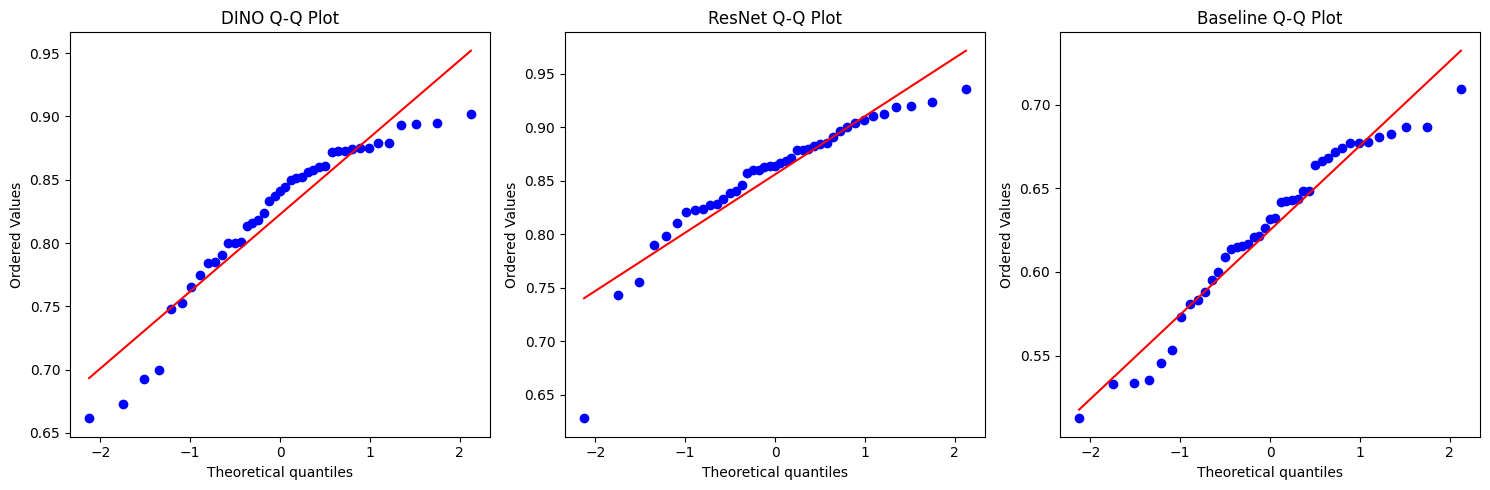

Shapiro-Wilk Test Results:
DINO:     W=0.8980, p=0.0014
ResNet50: W=0.8681, p=0.0002
Baseline: W=0.9492, p=0.0658


In [43]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Initialize lists to store IoU scores
dino_scores = []
resnet_scores = []
baseline_scores = []

# Load per-image IoU scores from 5 folds
for fold in range(1,6):
    dino_path = f"exports/dino/dino_np/dino_fdnzv5c2_e399_per_image_iou_fold{fold}.npy"
    resnet_path = f"exports/unet/resnet_np/resnet50_per_image_iou_fold{fold}.npy"
    baseline_path = f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy"

    dino_scores.extend(np.load(dino_path))
    resnet_scores.extend(np.load(resnet_path))
    baseline_scores.extend(np.load(baseline_path))

# Run Shapiro-Wilk test for normality
shapiro_dino = stats.shapiro(dino_scores)
shapiro_resnet = stats.shapiro(resnet_scores)
shapiro_baseline = stats.shapiro(baseline_scores)

# Create Q-Q plots to visually assess normality
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
stats.probplot(dino_scores, dist="norm", plot=axes[0])
axes[0].set_title("DINO Q-Q Plot")

stats.probplot(resnet_scores, dist="norm", plot=axes[1])
axes[1].set_title("ResNet Q-Q Plot")

stats.probplot(baseline_scores, dist="norm", plot=axes[2])
axes[2].set_title("Baseline Q-Q Plot")

plt.tight_layout()
plt.show()

# Print Shapiro-Wilk test results
print("Shapiro-Wilk Test Results:")
print(f"DINO:     W={shapiro_dino.statistic:.4f}, p={shapiro_dino.pvalue:.4f}")
print(f"ResNet50: W={shapiro_resnet.statistic:.4f}, p={shapiro_resnet.pvalue:.4f}")
print(f"Baseline: W={shapiro_baseline.statistic:.4f}, p={shapiro_baseline.pvalue:.4f}")